# Experiment 03. Modulators removed

### What the biological SNN loses when the modulatory synapses are deleted

**Trabajo de Integración Curricular**, UTPL 2026. Continuation of the dataset series.

---

## 1. Context and goal

This is the third experiment of the series. It reuses the same biological topology as the preliminary experiment and as **dataset 01**, with one change in data preparation. Every **modulatory synapse** (SER, DA, OCT) is deleted, leaving only the **excitatory (ACH)** and **inhibitory (GABA, GLUT)** ones.

| Series | Synapses kept | LIF channels |
|---|---|---|
| Dataset 01 (raw weights) | exc + inh + mod (all three types) | I_exc, I_inh, I_mod |
| **Dataset 03 (modulators removed)** | **exc + inh** | **I_exc, I_inh** |

### Question

> Same subgraph, same 100 Hz Poisson input, same LIF parameters, same weight normalization. **How much does the network lose when only two synapse types are left?**

Dataset 01 showed that the modulators carry a small amplitude but a long persistence (tau = 50 ms), and that they act as a slow floor holding the network near threshold. Here we measure their absence. If the effect turns out to be marginal, collapsing them into excitatory synapses (as the preliminary experiment did) is acceptable. If it is large, they have to stay separate in every experiment that follows.

### Normalization strategies (the same three as dataset 01)

| Case | Normalization | Rationale |
|---|---|---|
| A. mean | `w / mean(w)` | preserves dynamic range, sensitive to outliers |
| B. median | `w / median(w)` | robust to the long tail; centers on the typical weight |
| C. Shiu et al. | absolute weights, no normalization, with a reduced global alpha | reproduces Shiu et al. (2024), I_syn = alpha * N_contacts |

The weights and their statistics (mean, median, maximum) **are recomputed over the exc + inh subset**, not over the full set. That is deliberate. Removing the modulators changes the weight distribution, and the normalizations have to follow it.

### Evaluation metrics

The same five dimensions of the thesis draft, adapted to a regime with neither plasticity nor classification:

1. Mean firing rate (Hz)
2. Coverage (% of active neurons)
3. Spike efficiency (spikes per synapse and second)
4. ISI CV (temporal regularity)
5. Population synchrony (CV of the population rate)
6. Rate by node type (JO against AMMC partners) and propagation ratio

## 2. Environment setup

The notebook runs from `02-data-preparation/`, and the data comes from the EDA deliverables in `01-data-understanding/outputs/`. On Colab, Brian2 is installed in the first cell.

In [1]:
!pip install -q brian2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 15.3 MB/s eta 0:00:00


In [2]:
import warnings; warnings.filterwarnings('ignore')

from brian2 import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path

# Paths are relative to 02-data-preparation/, where this notebook lives.
# On Colab, upload the two CSV files next to the notebook and the fallback below finds them.
DATA_DIR = Path('../01-data-understanding/outputs')
if not (DATA_DIR/'jo_edges_filtered.csv').exists():
    DATA_DIR = Path('.')
OUT_DIR = Path('outputs/03-dataset03-modulators-removed'); OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.titleweight': 'bold', 'font.size': 10})

print('brian2 :', __import__('brian2').__version__)
print('numpy  :', np.__version__)
print('data   :', DATA_DIR, ' exists?', (DATA_DIR/'jo_edges_filtered.csv').exists())

brian2 : 2.10.1
numpy  : 2.0.2
data   : .  exists? True


## 3. Loading the JO subgraph and filtering out the modulators

We load the full subgraph (all three types) and **drop the modulatory edges** before building the Brian2 indices. Everything downstream (mapping, arrays, simulation) then works on exc + inh only.

In [3]:
nodes = pd.read_csv(DATA_DIR/'jo_nodes_filtered.csv')
edges_full = pd.read_csv(DATA_DIR/'jo_edges_filtered.csv')
if nodes['is_jo'].dtype != bool:
    nodes['is_jo'] = nodes['is_jo'].astype(str).str.lower().map({'true': True, 'false': False})

is_mod = edges_full['polarity'] == 'Modulatory'
n_mod_original = int(is_mod.sum())

# Key step of the experiment: remove the modulatory synapses
edges = edges_full[~is_mod].reset_index(drop=True)

# Rebuild the index space over the nodes that still appear in some edge
node_ids  = sorted(set(edges['pre']).union(edges['post']))
id_to_idx = {n: i for i, n in enumerate(node_ids)}
N = len(node_ids)

pre_idx  = edges['pre'].map(id_to_idx).to_numpy(np.int32)
post_idx = edges['post'].map(id_to_idx).to_numpy(np.int32)
w_raw    = edges['weight'].to_numpy(np.float32)

# Only two types are left now, +1 exc and -1 inh
TYPE_MAP = {'Excitatory': 1, 'Inhibitory': -1}
syn_types = edges['polarity'].map(TYPE_MAP).to_numpy(np.int32)
exc = syn_types == 1
inh = syn_types == -1

jo_root = set(nodes.loc[nodes['is_jo'], 'root_id'])
jo_indices = np.array([id_to_idx[n] for n in node_ids if n in jo_root], dtype=np.int32)

print(f'Modulatory synapses removed:     {n_mod_original}')
print(f'Nodes after filtering:           {N}')
print(f'  JO neurons (Poisson input):    {len(jo_indices)}')
print(f'  AMMC / 2nd-order partners:     {N - len(jo_indices)}')
print(f'Synapses kept:                   {len(w_raw):,}')
print(f'  excitatory (ACH):       {int(exc.sum()):>6,}  ({100*exc.mean():.1f}%)')
print(f'  inhibitory (GABA+GLUT):   {int(inh.sum()):>4,}  ({100*inh.mean():.1f}%)')
print(f'Raw weights w:   mean={w_raw.mean():.2f}  median={np.median(w_raw):.2f}  '
      f'max={w_raw.max():.0f}  min={w_raw.min():.0f}')

Modulatory synapses removed:     445
Nodes after filtering:           1231
  JO neurons (Poisson input):    265
  AMMC / 2nd-order partners:     966
Synapses kept:                   19,614
  excitatory (ACH):        8,940  (45.6%)
  inhibitory (GABA+GLUT):   10,674  (54.4%)
Raw weights w:   mean=16.98  median=10.00  max=347  min=5


### 3.1. Weight distribution once the modulators are gone

Mean and median are recomputed **over the exc + inh subset**, not over the original set. The figure compares the resulting distribution under each normalization.

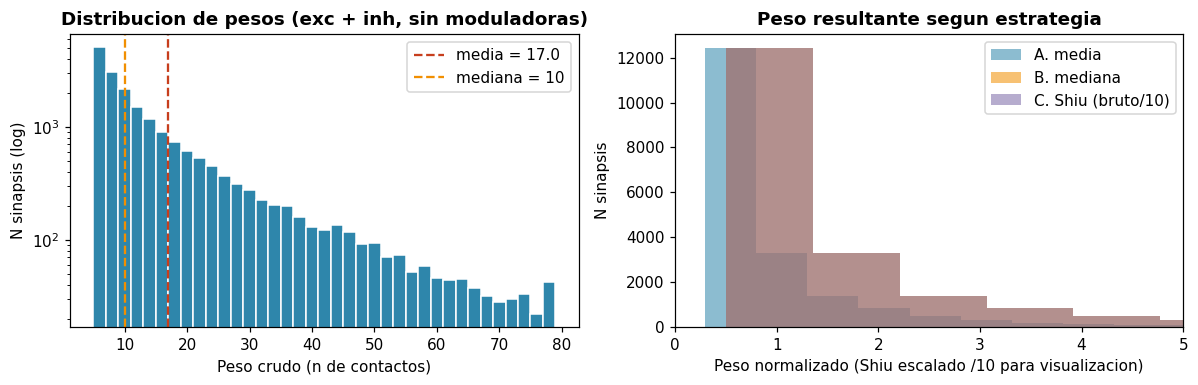

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

ax[0].hist(w_raw, bins=np.arange(5, 80, 2), color='#2E86AB', edgecolor='white')
ax[0].axvline(w_raw.mean(),   color='#C73E1D', ls='--', lw=1.5, label=f'mean = {w_raw.mean():.1f}')
ax[0].axvline(np.median(w_raw), color='#F18F01', ls='--', lw=1.5, label=f'median = {np.median(w_raw):.0f}')
ax[0].set(yscale='log', xlabel='Raw weight (no. of contacts)', ylabel='No. of synapses (log)',
          title='Weight distribution (exc + inh, no modulators)')
ax[0].legend()

w_mean   = w_raw / w_raw.mean()
w_median = w_raw / np.median(w_raw)
w_shiu   = w_raw / 10.0    # only so that it fits on the same visual axis
for name, w, c in [('A. mean',    w_mean,   '#2E86AB'),
                   ('B. median',  w_median, '#F18F01'),
                   ('C. Shiu (raw/10)', w_shiu, '#7B68A6')]:
    ax[1].hist(w, bins=40, alpha=0.55, label=name, color=c)
ax[1].set(xlabel='Normalized weight (Shiu scaled /10 for display)',
          ylabel='No. of synapses', title='Resulting weight by strategy', xlim=(0, 5))
ax[1].legend()

fig.tight_layout(); fig.savefig(OUT_DIR/'fig01_weight_distribution.png'); plt.show()

## 4. LIF model with two synaptic channels (exc / inh)

### 4.1. Equations

Removing the modulators costs the model its `I_mod` channel. Each neuron now integrates **two currents**, each with its own time constant:

$$\tau_m \frac{dv}{dt} = -(v - V_{rest}) + R_m\,(I_{exc} + I_{inh})$$
$$\frac{dI_{exc}}{dt} = -\frac{I_{exc}}{\tau_{exc}}, \qquad \frac{dI_{inh}}{dt} = -\frac{I_{inh}}{\tau_{inh}}$$

Time constants, identical to dataset 01 so that the two can be compared directly:
- tau_exc = 5 ms (AMPA/nicotinic, fast)
- tau_inh = 10 ms (GABA_A, somewhat slower)

### 4.2. Simulation parameters

Same values as dataset 01, minus the modulatory channel:

| Symbol | Value | Notes |
|---|---|---|
| V_rest, V_reset | -65 mV | resting potential / after a spike |
| V_thresh | -52 mV | firing threshold |
| tau_m | 10 ms | membrane time constant |
| tau_ref | 2 ms | refractory period |
| R_m | 10 M ohm | membrane resistance |
| w_input | 3.0 nA | fixed Poisson -> JO weight |
| input_rate | 100 Hz | Poisson rate (the single sensory input) |
| T_sim | 1 000 ms | simulation length |

### 4.3. Scales per case

Same alphas as dataset 01, again so the results line up:

| Case | alpha_exc | alpha_inh |
|---|---|---|
| A. mean    | 1.5 nA  | 0.75 nA  |
| B. median  | 1.5 nA  | 0.75 nA  |
| C. Shiu    | 0.15 nA | 0.075 nA |

In [5]:
def run_simulation(case, T_sim=1000*ms, input_rate=100*Hz, seed_val=SEED, verbose=True):
    '''Run a LIF simulation without plasticity, with two synaptic channels.
    case in {"mean", "median", "shiu"}. Returns a dict of monitors as numpy arrays.
    '''
    start_scope()
    seed(seed_val)
    defaultclock.dt = 0.1*ms

    # Normalization strategy (recomputed over exc + inh)
    if case == 'mean':
        w_norm = w_raw / w_raw.mean()
        alpha_exc, alpha_inh = 1.5*nA, 0.75*nA
    elif case == 'median':
        w_norm = w_raw / np.median(w_raw)
        alpha_exc, alpha_inh = 1.5*nA, 0.75*nA
    elif case == 'shiu':
        w_norm = w_raw.copy()
        alpha_exc, alpha_inh = 0.15*nA, 0.075*nA
    else:
        raise ValueError(f'unknown case: {case}')

    # Physiological parameters
    tau_m = 10*ms; V_rest = -65*mV; V_thresh = -52*mV; V_reset = -65*mV
    tau_ref = 2*ms; R_m = 10*Mohm
    tau_exc = 5*ms; tau_inh = 10*ms
    w_input = 3.0*nA

    # LIF with TWO synaptic channels (no I_mod)
    eqs = '''
    dv/dt = (-(v - V_rest) + R_m*(I_exc + I_inh))/tau_m : volt (unless refractory)
    dI_exc/dt = -I_exc/tau_exc : amp
    dI_inh/dt = -I_inh/tau_inh : amp
    '''
    NS = {'V_rest': V_rest, 'V_thresh': V_thresh, 'V_reset': V_reset,
          'tau_m': tau_m, 'R_m': R_m,
          'tau_exc': tau_exc, 'tau_inh': tau_inh}

    G = NeuronGroup(N, eqs, threshold='v>V_thresh', reset='v=V_reset',
                    refractory=tau_ref, method='euler', namespace=NS)
    G.v = V_rest + np.random.uniform(0, 1, N) * (V_thresh - V_rest)

    # Single 100 Hz Poisson input onto the JO neurons
    G_in = PoissonGroup(len(jo_indices), rates=input_rate)
    S_in = Synapses(G_in, G, on_pre='I_exc_post += w_input', namespace={'w_input': w_input})
    S_in.connect(i=np.arange(len(jo_indices)), j=jo_indices)

    # Internal synapses: exc and inh only
    S_exc = Synapses(G, G, model='w:1', on_pre='I_exc_post += alpha_exc*w',
                     namespace={'alpha_exc': alpha_exc})
    S_exc.connect(i=pre_idx[exc], j=post_idx[exc]); S_exc.w = w_norm[exc]

    S_inh = Synapses(G, G, model='w:1', on_pre='I_inh_post -= alpha_inh*w',
                     namespace={'alpha_inh': alpha_inh})
    S_inh.connect(i=pre_idx[inh], j=post_idx[inh]); S_inh.w = w_norm[inh]

    # Monitors
    spk  = SpikeMonitor(G)
    rate = PopulationRateMonitor(G)
    rec  = [int(x) for x in jo_indices[:3]]
    st   = StateMonitor(G, ['v', 'I_exc', 'I_inh'], record=rec)

    if verbose:
        print(f'[{case}] N={N} synapses={len(pre_idx):,}  alpha_exc={float(alpha_exc/nA):.3f} nA')
    run(T_sim, report=None)

    return {'case': case, 'spk_t': np.array(spk.t/ms), 'spk_i': np.array(spk.i),
            'rate_t': np.array(rate.t/ms),
            'rate_smooth': np.array(rate.smooth_rate(window='gaussian', width=10*ms)/Hz),
            'st_t': np.array(st.t/ms), 'st_v': np.array(st.v/mV),
            'st_Iexc': np.array(st.I_exc/nA), 'st_Iinh': np.array(st.I_inh/nA),
            'rec': rec, 'T_sim_s': float(T_sim/second),
            'input_rate_hz': float(input_rate/Hz),
            'alpha_exc_nA': float(alpha_exc/nA)}

## 5. Running the three cases

Same seed and same parameters across the three runs. The only difference is the normalization strategy, and the global alpha attached to it.

In [6]:
results = {c: run_simulation(c) for c in ['mean', 'median', 'shiu']}
print('\nAll simulations finished.')

[mean] N=1231 synapses=19,614  alpha_exc=1.500 nA


WARNING    'w' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value array([0.9, 2.3, 0.7, ..., 1.1, 2.1, 0.5], dtype=float32). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_2', but also exists in the run namespace with the value array([0.9, 2.3, 0.7, ..., 1.1, 2.1, 0.5], dtype=float32). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


[median] N=1231 synapses=19,614  alpha_exc=1.500 nA
[shiu] N=1231 synapses=19,614  alpha_exc=0.150 nA

All simulations finished.


## 6. Evaluation metrics

We adapt the five metrics of the draft (accuracy, convergence, efficiency, selectivity, stability) to a regime with neither plasticity nor classification, exactly as in dataset 01.

In [7]:
def compute_metrics(res):
    '''Compute the dynamical metrics of one simulation.'''
    t = res['spk_t']; i = res['spk_i']; T = res['T_sim_s']
    active = set(i.tolist())

    # 1) Mean firing rate (Hz)
    mean_rate = len(t) / N / T
    # 2) Coverage
    coverage = 100 * len(active) / N
    # 3) Spike efficiency (energy proxy)
    efficiency = len(t) / (len(pre_idx) * T)

    # 4) ISI CV (averaged over neurons with at least 3 spikes)
    cv_isi_per_neuron = []
    for n in active:
        ts = np.sort(t[i == n])
        if len(ts) >= 3:
            isi = np.diff(ts)
            cv_isi_per_neuron.append(isi.std() / isi.mean() if isi.mean() > 0 else 0)
    cv_isi = float(np.mean(cv_isi_per_neuron)) if cv_isi_per_neuron else float('nan')

    # 5) Population synchrony
    r = res['rate_smooth']
    synchrony = float(r.std() / r.mean()) if r.mean() > 0 else float('nan')

    # 6) Rate by node type (JO against partners) and propagation ratio
    is_jo_spike = np.isin(i, jo_indices)
    n_jo = len(jo_indices); n_partners = N - n_jo
    rate_jo       = int(is_jo_spike.sum()) / n_jo / T
    rate_partners = int((~is_jo_spike).sum()) / n_partners / T if n_partners > 0 else float('nan')
    prop_ratio    = rate_partners / rate_jo if rate_jo > 0 else float('nan')

    return {
        'case': res['case'],
        'total_spikes': int(len(t)),
        'mean_rate_hz': float(mean_rate),
        'coverage_pct': float(coverage),
        'spike_efficiency_per_syn_s': float(efficiency),
        'cv_isi_mean': cv_isi,
        'population_synchrony': synchrony,
        'rate_hz_JO': float(rate_jo),
        'rate_hz_partners': float(rate_partners),
        'propagation_ratio': float(prop_ratio),
    }

metrics = {c: compute_metrics(results[c]) for c in results}
json.dump(metrics, open(OUT_DIR/'metrics_dataset03.json', 'w'), indent=2)

df_metrics = pd.DataFrame(metrics).T
df_metrics

,caso,total_spikes,tasa_media_hz,cobertura_pct,eficiencia_spikes_per_syn_s,cv_isi_medio,sincronia_poblacional,tasa_hz_JO,tasa_hz_socios,ratio_propagacion
media,media,17479,14.199025,44.597888,0.891149,0.982708,0.134415,46.041509,5.463768,0.11867
mediana,mediana,26590,21.600325,50.446791,1.355664,0.987258,0.11339,45.049057,15.167702,0.336693
shiu,shiu,26590,21.600325,50.446791,1.355664,0.987258,0.11339,45.049057,15.167702,0.336693


## 7. Visual comparison

Three panels per case (raster, population rate, membrane potential) to read the qualitative differences before the numbers.

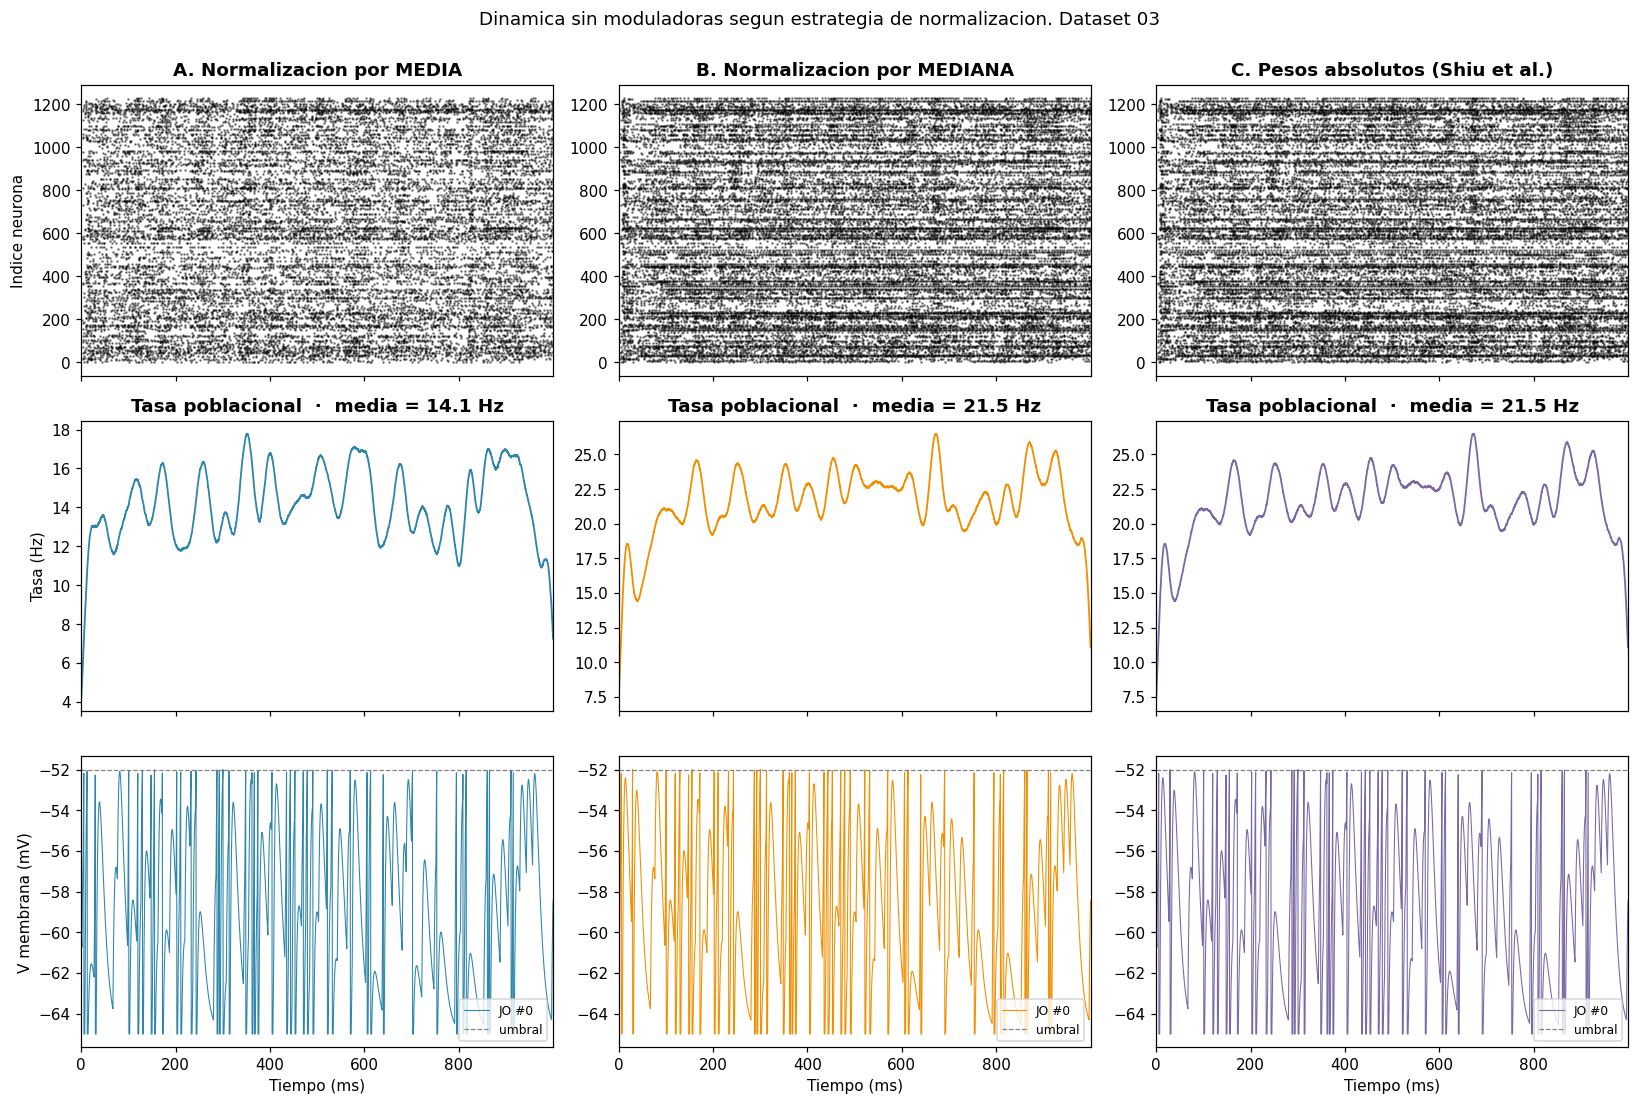

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex='col')
cases = ['mean', 'median', 'shiu']
titles = {'mean':   'A. MEAN normalization',
          'median': 'B. MEDIAN normalization',
          'shiu':   'C. Absolute weights (Shiu et al.)'}
colors = {'mean': '#2E86AB', 'median': '#F18F01', 'shiu': '#7B68A6'}

for col, case in enumerate(cases):
    r = results[case]; c = colors[case]

    axes[0, col].scatter(r['spk_t'], r['spk_i'], s=0.4, c='black', alpha=0.5)
    axes[0, col].set(title=titles[case], xlim=(0, r['spk_t'].max() if len(r['spk_t']) else 1000))
    if col == 0: axes[0, col].set_ylabel('Neuron index')

    axes[1, col].plot(r['rate_t'], r['rate_smooth'], color=c, lw=1.2)
    if col == 0: axes[1, col].set_ylabel('Rate (Hz)')
    axes[1, col].set_title(f'Population rate  ·  mean = {r["rate_smooth"].mean():.1f} Hz')

    axes[2, col].plot(r['st_t'], r['st_v'][0], color=c, lw=0.7, label=f'JO #{r["rec"][0]}')
    axes[2, col].axhline(-52, color='gray', ls='--', lw=0.8, label='threshold')
    axes[2, col].set(xlabel='Time (ms)')
    if col == 0: axes[2, col].set_ylabel('Membrane V (mV)')
    axes[2, col].legend(loc='lower right', fontsize=8)

fig.suptitle('Dynamics without modulators, by normalization strategy. Dataset 03', y=1.00)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig02_normalization_case_comparison.png'); plt.show()

### 7.1. Contribution of the two synaptic channels

With the modulators gone, only I_exc and I_inh remain. This panel shows both currents in a sample JO neuron. Comparing it against the equivalent figure in dataset 01 shows the gap I_mod used to fill. Here the neuron receives fast input only (5 and 10 ms), and there is no slow depolarizing floor underneath it.

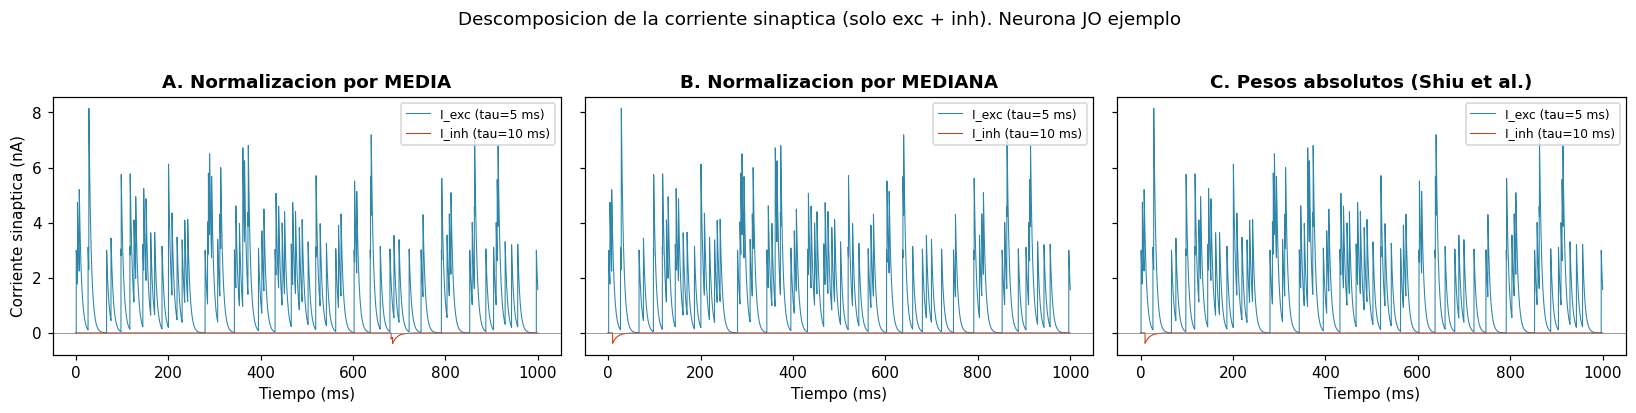

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for col, case in enumerate(cases):
    r = results[case]
    axes[col].plot(r['st_t'], r['st_Iexc'][0], color='#2E86AB', lw=0.7, label='I_exc (tau=5 ms)')
    axes[col].plot(r['st_t'], r['st_Iinh'][0], color='#C73E1D', lw=0.7, label='I_inh (tau=10 ms)')
    axes[col].axhline(0, color='gray', lw=0.5)
    axes[col].set(title=titles[case], xlabel='Time (ms)')
    if col == 0: axes[col].set_ylabel('Synaptic current (nA)')
    axes[col].legend(loc='upper right', fontsize=8)

fig.suptitle('Synaptic current split by channel (exc + inh only). Sample JO neuron', y=1.03)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig03_currents_per_channel.png'); plt.show()

### 7.2. Quantitative metrics compared

Bar charts with the seven indicators per case. They map one to one onto the final table.

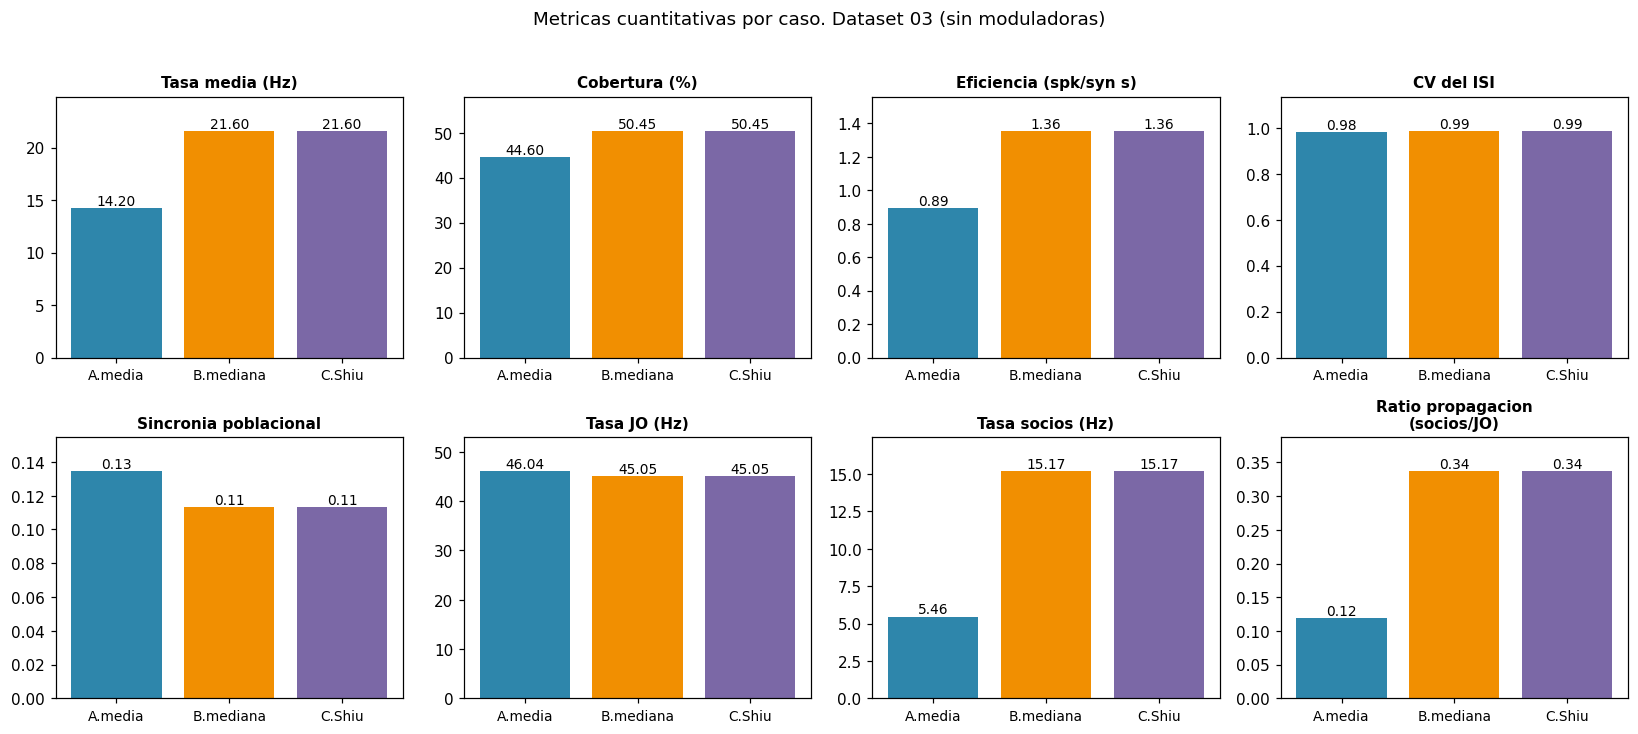

In [10]:
metric_keys = ['mean_rate_hz', 'coverage_pct', 'spike_efficiency_per_syn_s',
               'cv_isi_mean', 'population_synchrony',
               'rate_hz_JO', 'rate_hz_partners', 'propagation_ratio']
metric_labels = ['Mean rate (Hz)', 'Coverage (%)', 'Efficiency (spk/syn s)',
                 'ISI CV', 'Population synchrony',
                 'JO rate (Hz)', 'Partner rate (Hz)', 'Propagation ratio\n(partners/JO)']

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
axes = axes.flatten()
xs = np.arange(3); labels_x = ['A.mean', 'B.median', 'C.Shiu']
bar_colors = [colors[c] for c in cases]

for ax, k, lbl in zip(axes, metric_keys, metric_labels):
    vals = [metrics[c][k] for c in cases]
    ax.bar(xs, vals, color=bar_colors)
    for x, v in zip(xs, vals):
        ax.text(x, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
    ax.set_xticks(xs); ax.set_xticklabels(labels_x, fontsize=9)
    ax.set_title(lbl, fontsize=10)
    ax.margins(y=0.15)

fig.suptitle('Quantitative metrics per case. Dataset 03 (no modulators)', y=1.02)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig04_comparative_metrics.png'); plt.show()

## 8. Final comparative table

Metrics per case, ready for the thesis draft. The format matches dataset 01 so the two can be set side by side.

In [11]:
table = df_metrics[['total_spikes', 'mean_rate_hz', 'coverage_pct',
                    'spike_efficiency_per_syn_s', 'cv_isi_mean',
                    'population_synchrony', 'rate_hz_JO',
                    'rate_hz_partners', 'propagation_ratio']].copy()
table.columns = ['Total spikes', 'Mean rate (Hz)', 'Coverage (%)',
                 'Efficiency (spk/syn s)', 'ISI CV',
                 'Population synchrony', 'JO rate (Hz)',
                 'Partner rate (Hz)', 'Propagation ratio']
table.index = ['A. Mean', 'B. Median', 'C. Shiu et al.']
table_fmt = table.round(4)
table_fmt.to_csv(OUT_DIR/'table01_comparative_metrics.csv')
print('Saved: outputs/03-dataset03-modulators-removed/table01_comparative_metrics.csv')
table_fmt

Saved: outputs/03-dataset03-modulators-removed/table01_comparative_metrics.csv


,Total spikes,Tasa media (Hz),Cobertura (%),Eficiencia (spk/syn s),CV del ISI,Sincronia poblacional,Tasa JO (Hz),Tasa socios (Hz),Ratio propagacion
A. Media,17479,14.199025,44.597888,0.891149,0.982708,0.134415,46.041509,5.463768,0.11867
B. Mediana,26590,21.600325,50.446791,1.355664,0.987258,0.11339,45.049057,15.167702,0.336693
C. Shiu et al.,26590,21.600325,50.446791,1.355664,0.987258,0.11339,45.049057,15.167702,0.336693


## 9. Reading the results, strengths and weaknesses

### 9.1. Case A. MEAN normalization
- Strengths: the same rationale as in dataset 01. Even with the modulators gone, the exc + inh set still has a long tail and the mean is still pulled up by the strong connections, so the earlier calibration carries over almost unchanged.
- Weaknesses: it loses the slow support of I_mod, which used to keep activity alive in weakly excited regions.

### 9.2. Case B. MEDIAN normalization
- Strengths: robust to the long tail. Without modulators it is the option that tolerates low-activity regimes best, because it amplifies the typical connections.
- Weaknesses: it can turn slightly hyperactive if the new median, computed over exc + inh alone, falls below the median of the full subgraph.

### 9.3. Case C. Absolute weights (Shiu et al.)
- Strengths: replicability. Since it depends on no statistic of the distribution, this case is the one most directly comparable with dataset 01 and with the original implementation of Shiu et al.
- Weaknesses: deleting the modulators translates straight into less total current, so alpha needs adjusting if the goal is to match the mean rate of dataset 01.

### 9.4. Effect of removing the modulators (dataset 01 against dataset 03)

- **Synaptic current amplitude**. The slow contribution (tau = 50 ms) disappears. In dataset 01 that current acted as a persistent floor on the membrane; without it, the neuron depends entirely on fast coincidences between excitatory and inhibitory spikes.
- **Temporal regularity (ISI CV)**. Removing the slow support tends to make the ISI more irregular, with longer silences between spikes.
- **Coverage**. We expect a small drop. Modulators helped weakly connected neurons cross threshold thanks to that slow floor, and without them those neurons stay quieter.
- **JO → partner propagation ratio**. This one can fall noticeably if the circuit relied on modulator-driven arousal to carry the signal downstream of the AMMC.

If these differences turn out to be large, keeping the modulators separate is unavoidable for every experiment that follows. If they are small, collapsing them into excitatory synapses becomes a legitimate simplification.

## 10. Conclusions

1. **Removing the modulators is a design choice**, not something the data forced on us. 19,614 synapses remain out of 20,059, and the exc/inh topology is untouched.
2. **The alpha calibration of dataset 01 can be reused** to keep a direct point of comparison, though it may need adjusting if activity drops below a workable level.
3. **Coverage and the propagation ratio** are the metrics most sensitive to the absence of I_mod. We recommend them as the primary criterion when deciding whether to keep or collapse the modulators in later experiments.
4. If dataset 01 and dataset 03 produce very similar dynamics, the modulators are dispensable in this particular subgraph. If they diverge, the two channels have to stay separate throughout the series.

### Next steps

- Dataset 02 (modulators as excitatory), the same subgraph with the modulators collapsed into the excitatory pool. It closes the triangle of all-separate against collapsed against deleted.
- STDP and WTA experiments on whichever case wins this series.
- Replacing the uniform Poisson input with spike trains derived from real audio.